In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt


import sklearn
sklearn.set_config(display="text")


이번에는 선형회귀를 기반으로 하는 Regresson 모형이 아닌, Tree나 신경망을 기반으로 하는 다른 머신러닝 모형을 학습하겠습니다.\
이번 실습에서 학습해볼 모델은 다음과 같습니다.

* 기본 Tree 계열
  - Decision tree
  - Random Forest

* 부스팅 Tree 계열
  - GBM
  - XG Boost
  - Light GBM

* 신경망 계열
  - MLP

먼저 저번 실습에서 사용한 데이터를 불러오고, 인구가 0이라 고령층, 유소년층 비율이 NaN값인 비시가지 지역은 제외하도록 하겠습니다.

In [2]:
pop_grid = gpd.read_file('data/pop_grid_ml.geojson', encoding="utf-8")
pop_grid = pop_grid[(pop_grid['elder_ratio'].notna())&(pop_grid['youth_ratio'].notna())]

## 9.1 기본 Tree 계열

### 9.1.1 Decision tree

Decision tree란 독립 변수에 따른 규칙을 적용하여 분류 또는 회귀분석을 수행하는 모형입니다. 예를 들어 거주인구가 10명 이상인 경우, 10명 이하인 경우처럼 특정 독립변수의 기준값을 바탕으로 조건을 만들고, 각 조건에 다른 하위세부조건을 계속 추가해나가는 방식으로 최적의 값을 예측해나갑니다. 마치 뻗어나가는 모습이 나무처럼 생겼다고 해서 Decision Tree라고 부릅니다

<img src="https://user-images.githubusercontent.com/49559408/66479241-1accac00-ead7-11e9-9484-1e191aa5b0a5.PNG" width="600" height="400" />

<center> 가장 간단한 Decision tree 원리 <center/>

<img src="https://miro.medium.com/v2/resize:fit:640/format:webp/1*IbJll98vSNx7sIIOiUEerw.png" width="600" height="400" />

<center> 실제로 모델이 복잡해지면 이렇게 됩니다... <center/>

#### 기본 모델 학습

In [3]:
# 먼저 학습을 진행하기 전 X, Y를 나누고, training set과 test set을 나누도록 하겠습니다.
X = pop_grid[['total_pop', 'elder_ratio', 'youth_ratio', 'industrial_ratio',
       'commercial_ratio', 'residential_ratio', 'dist_seoul_city_hall',
       'dist_gangnam_station']]
Y = pop_grid.emergency_no

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=100)
print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

(26665, 8)
(26665,)
(11429, 8)
(11429,)


In [4]:
# Decision tree 모델을 불러오고, 생성시키겠습니다.
from sklearn.tree import DecisionTreeRegressor
tree1 = DecisionTreeRegressor(random_state = 1)

# Decision tree 모델에 training set을 학습시킵니다.
tree1.fit(X_train, Y_train)

DecisionTreeRegressor(random_state=1)

In [5]:
# 학습한 모델을 바탕으로 test set의 예측값을 뽑아내고, 모델의 정확도를 검증합니다.
from sklearn import metrics

Y_train_pred = tree1.predict(X_train)
print('train RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred)))
print('train R-square:', metrics.r2_score(Y_train, Y_train_pred))

Y_test_pred = tree1.predict(X_test)
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

train RMSE: 0.0
train R-square: 1.0
test RMSE: 12.627600539648176
test R-square: -0.17589226393492274


In [6]:
# 앞으로 많은 모델에 대해서 정확도 검증을 할 예정이니, 함수화를 진행해줍니다
def print_accuracy(model):
    Y_train_pred = model.predict(X_train)
    print('train RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred)))
    print('train R-square:', metrics.r2_score(Y_train, Y_train_pred))

    Y_test_pred = model.predict(X_test)
    print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred)))
    print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

print_accuracy(tree1) #학습된 모델을 넣어준다

train RMSE: 0.0
train R-square: 1.0
test RMSE: 12.627600539648176
test R-square: -0.17589226393492274


test set의 R-square를 보면 음수가 나오는데, 이는 평균선보다도 예측력이 떨어지는 현상이 발생했음을 의미합니다.\
이에 반해 training set의 경우 R-square가 1이 나오는 것을 보니, training set에 과도하게 최적화되는 Overfitting이 발생한 것을 알 수 있습니다.

#### hyperparameter 조절하기

이러한 Overfitting을 방지하거나, 혹은 성능을 더 향상시키기 위해서 모델의 hyperparameter를 조절하여 모델의 구조를 바꿀 수 있습니다.\
저번 실습 때 Ridge와 Lasso 모형에서 hyperparameter인 alpha 값을 다르게 주어 성능을 비교했던 것 기억나시나요?\
마찬가지로 Decision Tree에서도 hyperparameter를 조절할 수 있으며, 여러 hyperparameter들이 있지만, 대표적인 2가지만 다뤄보도록 하겠습니다.

- max_depth : 트리의 최대 깊이(하위 세부조건이 몇 단계까지 내려갈 수 있는가?)
- min_samples_leaf : 또 다른 노드를 만들 수 있는 최소한의 샘플 수

이 외에도 min_samples_split, max_leaf_nodes, max_features 등이 있습니다... 시간이 많다면 도전\

In [7]:
#더 많은 하이퍼파라미터 확인
DecisionTreeRegressor?

Init signature:
DecisionTreeRegressor(
    *,
    criterion='squared_error',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=None,
    random_state=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    ccp_alpha=0.0,
    monotonic_cst=None,
)
Docstring:     
A decision tree regressor.

Read more in the :ref:`User Guide <tree>`.

Parameters
----------
criterion : {"squared_error", "absolute_error", "poisson"}, default="squared_error"
    The function to measure the quality of a split. Supported criteria
    are "squared_error" for the mean squared error, which is equal to
    variance reduction as feature selection criterion and minimizes the L2
    loss using the mean of each terminal node, "absolute_error" for the mean
    absolute error, which minimizes the L1 loss using the median of each terminal
    node, and "poisson" which uses reduction in Poisson deviance to find splits,
  

In [8]:
# hyperparameter를 지정하고, 모델을 학습시킵니다 (지정하지 않는 hyperparameter는 default 값이 들어가게됨)
tree2 = DecisionTreeRegressor(random_state = 1, max_depth=5, min_samples_leaf = 10)
tree2.fit(X_train, Y_train)

DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=1)

In [9]:
# 새로 학습시킨 모델의 정확도를 확인합니다.
print_accuracy(tree2)

train RMSE: 10.88938930517507
train R-square: 0.2004570474067695
test RMSE: 10.544159754621639
test R-square: 0.18012089607917603


이번의 경우 training set 대상 예측력과 test set 대상 예측력이 얼추 비슷해졌습니다. 이는 hyperparameter를 조절하여 overfitting을 막았기 때문입니다.

In [10]:
# 선형회귀모형과 비교했을 때 training set, test set 대상 예측력이 향상된 것을 확인 할 수 있습니다.
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, Y_train)

print_accuracy(linreg)

train RMSE: 11.115379515663241
train R-square: 0.16692645800120365
test RMSE: 10.548400226935124
test R-square: 0.17946131317893832


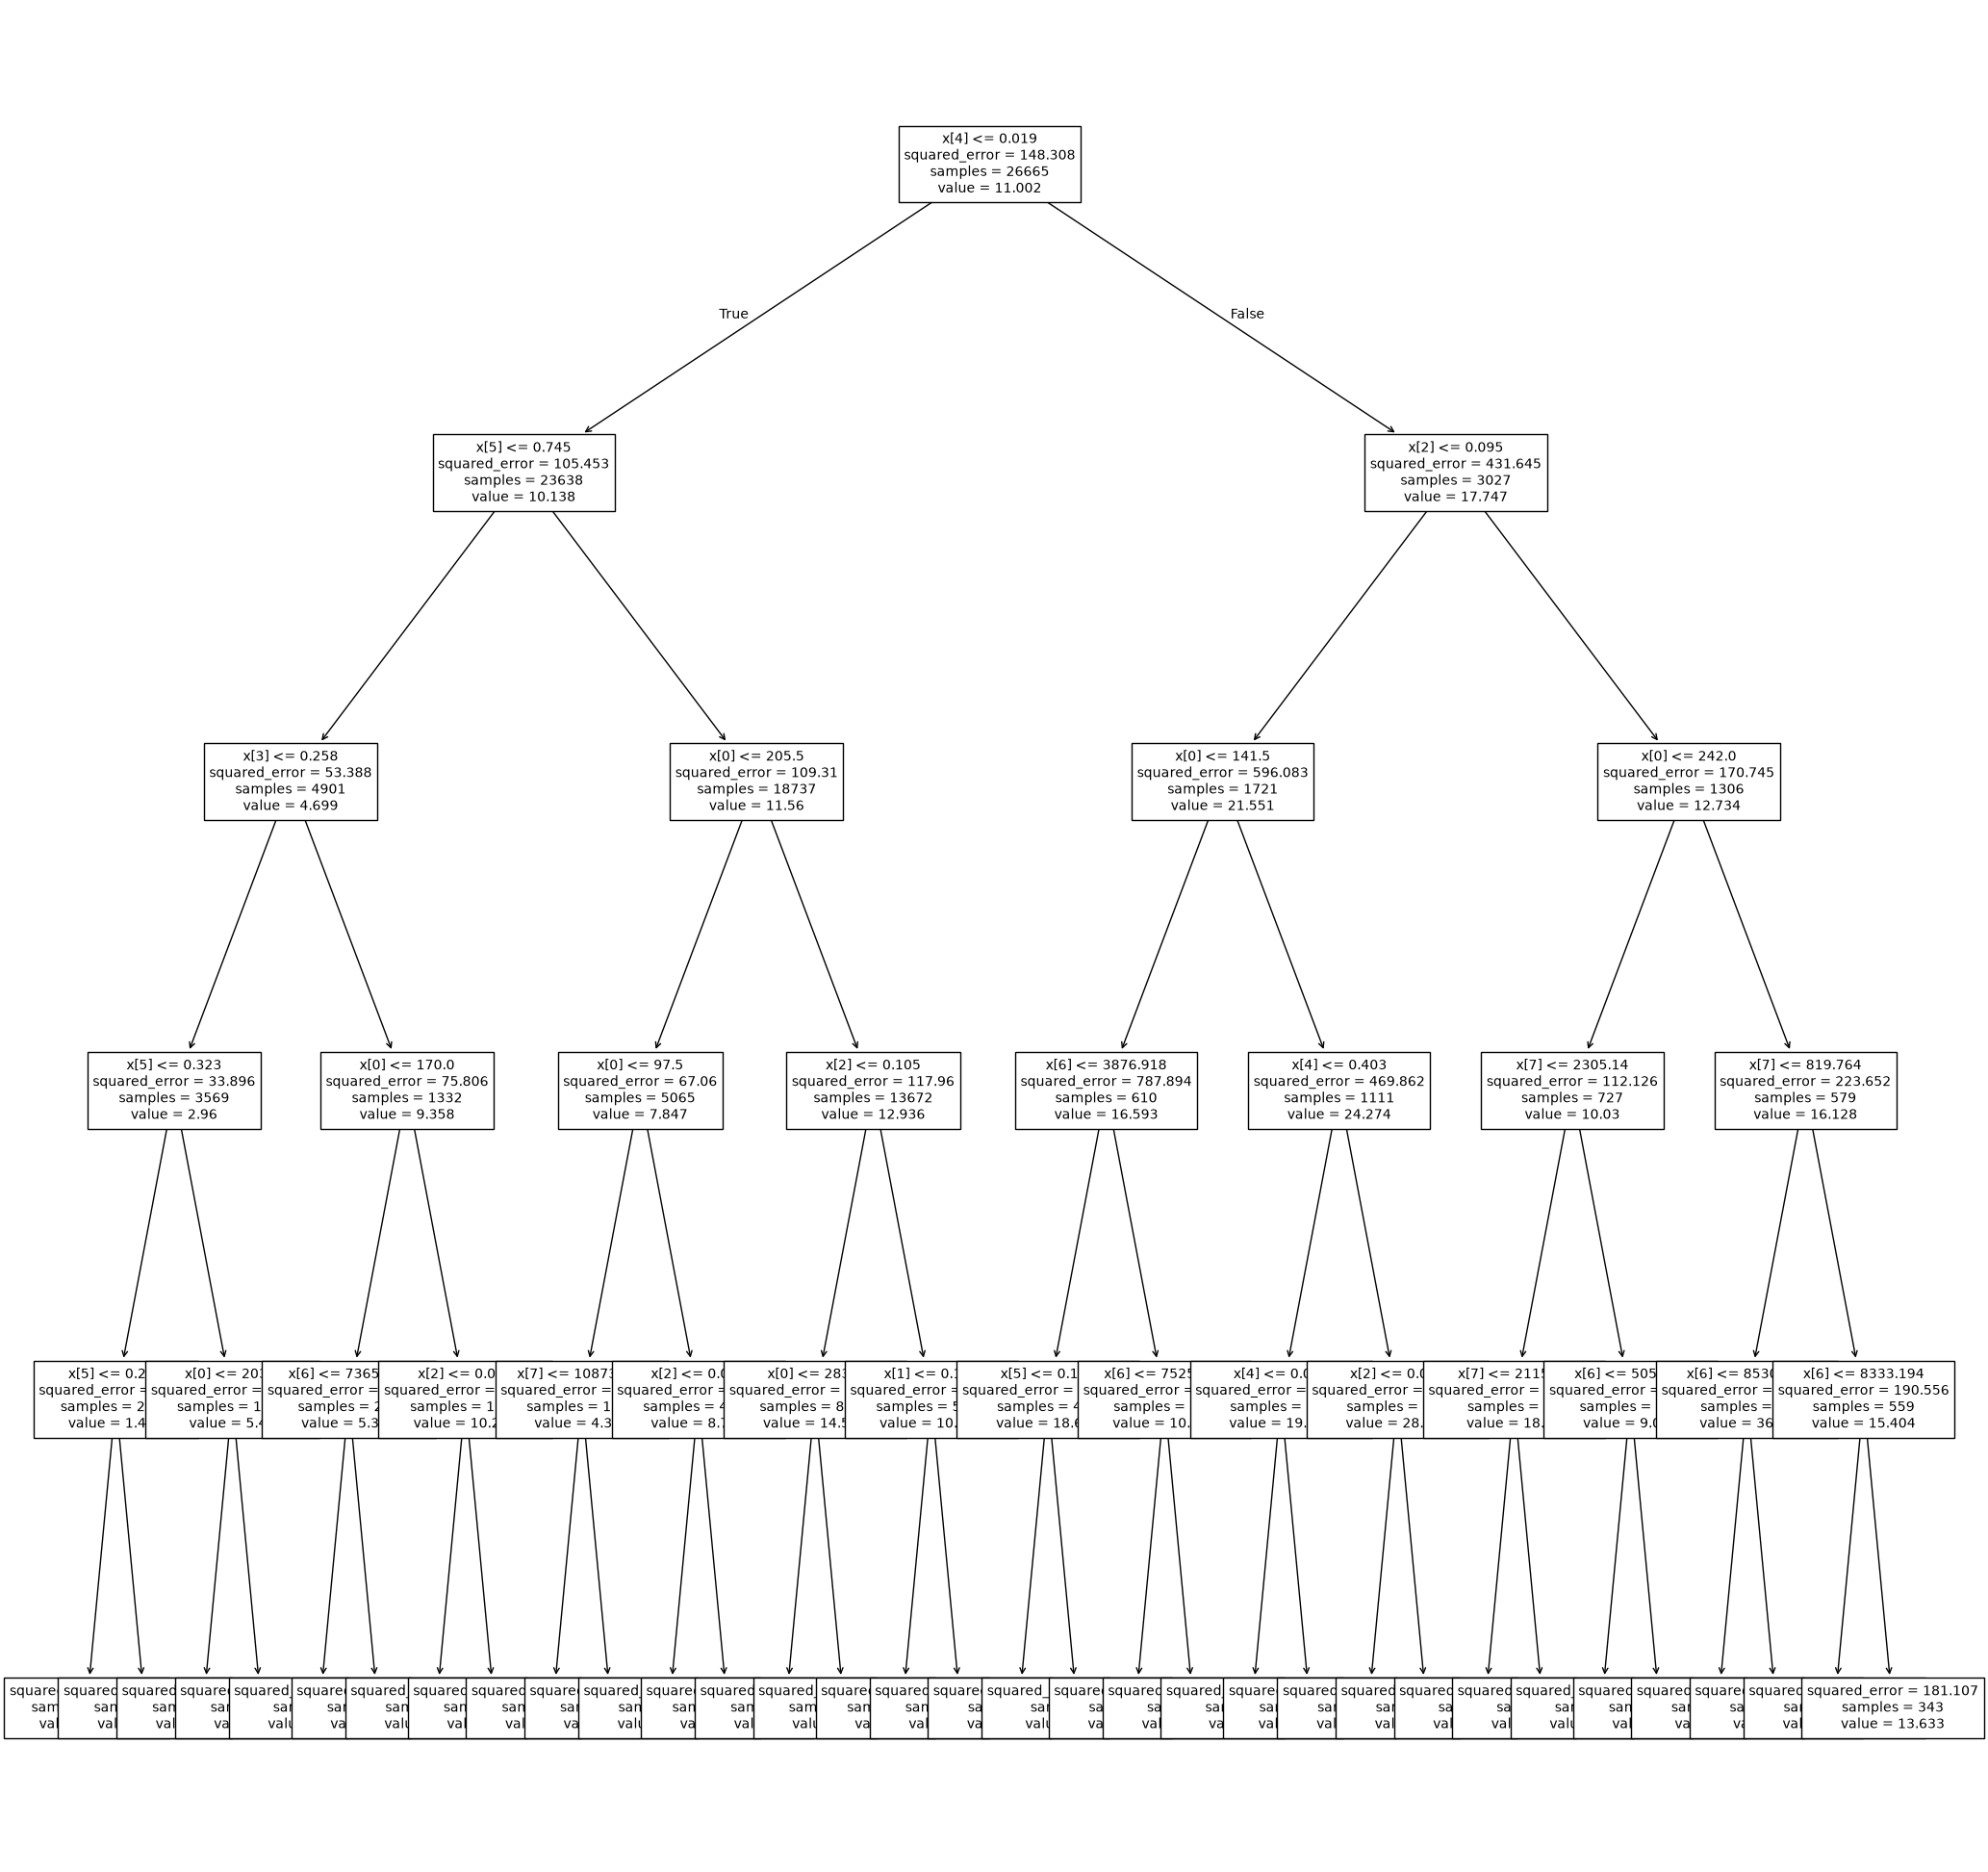

In [11]:
# Decision tree를 plot할 수 있습니다.
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(25, 25))
plot_tree(tree2, fontsize=10, ax=ax)
plt.show()

어떤 Hyperparameter들은 크게 설정할수록 모델이 복잡해집니다.(Decision Tree의 최대 깊이가 깊어질수록 복잡)\
**모델이 복잡하다고 예측력이 무조건 좋아지지 않습니다.** Training set에 너무 적합한 나머지 Test set을 맞추지 못하게 되기 때문입니다.\
Overfitting 현상을 방지하기 위해서  **데이터에 효과적이고, 적합한 복잡도를 가지는 모델을 선정하는 것이 중요**합니다.

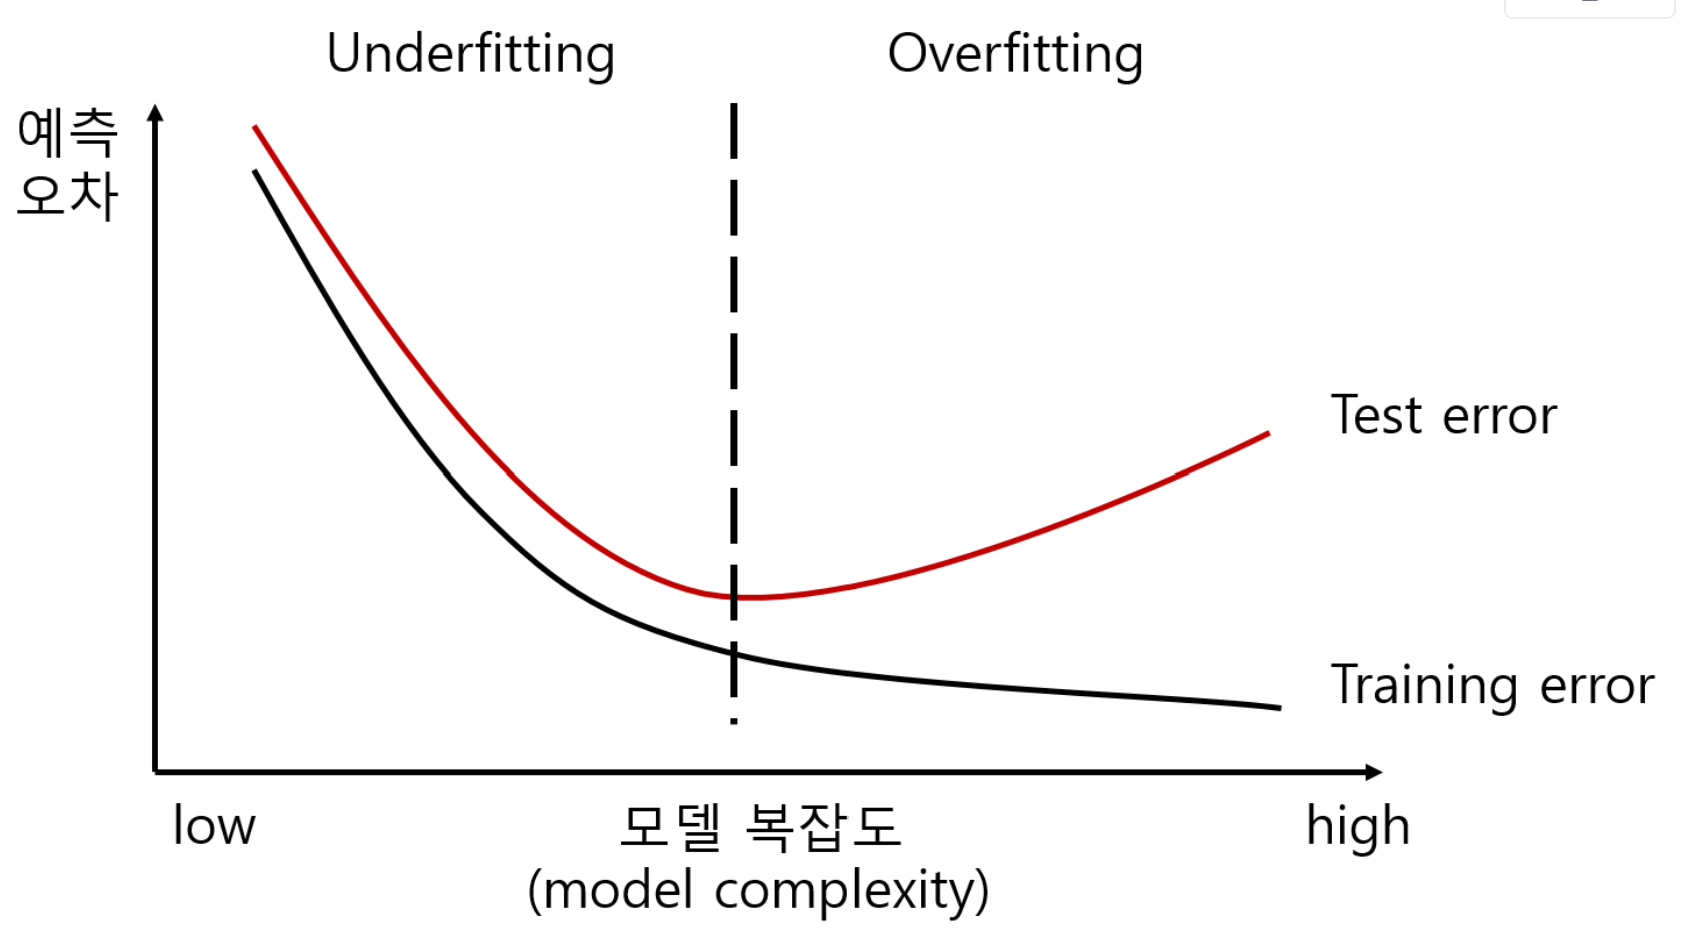

#### hyperparameter tuning

하지만 이렇게 일일히 hyperparameter를 바꿔가면서 최적 값을 찾는 것은 힘들겠죠? sklearn에서는 GridSearchCV함수를 제공하여 hyperparameter tuning을 빠르게 자동적으로 할 수 있도록 돕습니다.

In [12]:
from sklearn.model_selection import GridSearchCV

tree = DecisionTreeRegressor()    #모델 선언

# 테스트 해볼 hyperparameter와 그 값들을 딕셔너리로 선언합니다.
parameters = {'max_depth':[3,4,5,6,7,8,9,10],'min_samples_leaf':[2,3,5,10,15,20]}
grid_tree = GridSearchCV(tree, param_grid=parameters, scoring = 'r2',cv=3)
#r-square 값을 기준으로 최적의 모델을 찾는 Cross validation test 3회진행
#training set 안에서 다시 validation set을 일부 만들어, 이를 통해 검증

#parameter test 결과 출력
grid_tree.fit(X_train, Y_train)
scores = pd.DataFrame(grid_tree.cv_results_)
scores[['params','mean_test_score', 'rank_test_score', 'split0_test_score','split1_test_score', 'split2_test_score']]

,params,mean_test_score,rank_test_score,split0_test_score,split1_test_score,split2_test_score
0,"{'max_depth': 3, 'min_samples_leaf': 2}",0.135277,42,0.143077,0.153138,0.109617
1,"{'max_depth': 3, 'min_samples_leaf': 3}",0.135277,42,0.143077,0.153138,0.109617
2,"{'max_depth': 3, 'min_samples_leaf': 5}",0.135277,42,0.143077,0.153138,0.109617
3,"{'max_depth': 3, 'min_samples_leaf': 10}",0.135277,42,0.143077,0.153138,0.109617
4,"{'max_depth': 3, 'min_samples_leaf': 15}",0.135277,42,0.143077,0.153138,0.109617
5,"{'max_depth': 3, 'min_samples_leaf': 20}",0.135277,42,0.143077,0.153138,0.109617
6,"{'max_depth': 4, 'min_samples_leaf': 2}",0.147701,37,0.127949,0.176971,0.138181
7,"{'max_depth': 4, 'min_samples_leaf': 3}",0.153424,33,0.145152,0.176971,0.138149
8,"{'max_depth': 4, 'min_samples_leaf': 5}",0.154232,32,0.147576,0.176971,0.138149
9,"{'max_depth': 4, 'min_samples_leaf': 10}",0.160382,28,0.166027,0.176971,0.138149


In [13]:
#가장 최적의 parameter 출력
print(grid_tree.best_params_)

#가장 최적의 모델 가져오기
best_tree = grid_tree.best_estimator_

#최적의 모델을 test set에 적용해보기
best_pred = best_tree.predict(X_test)
print('R-square of best model:{:.4f}'.format(metrics.r2_score(Y_test, best_pred)))

{'max_depth': 9, 'min_samples_leaf': 10}
R-square of best model:0.1956


#### 변수 중요도 살펴보기

Decision Tree 모형에서는 회귀모형과 비슷하게 어떤 독립변수가 큰 영향을 미치는지 변수 중요도를 산출할 수 있습니다.

In [14]:
#최적 모델의 변수 별 가중치 뽑아보기
best_tree.feature_importances_

array([0.17173987, 0.06686118, 0.14221798, 0.03357078, 0.17094473,
       0.21698166, 0.11771015, 0.07997365])

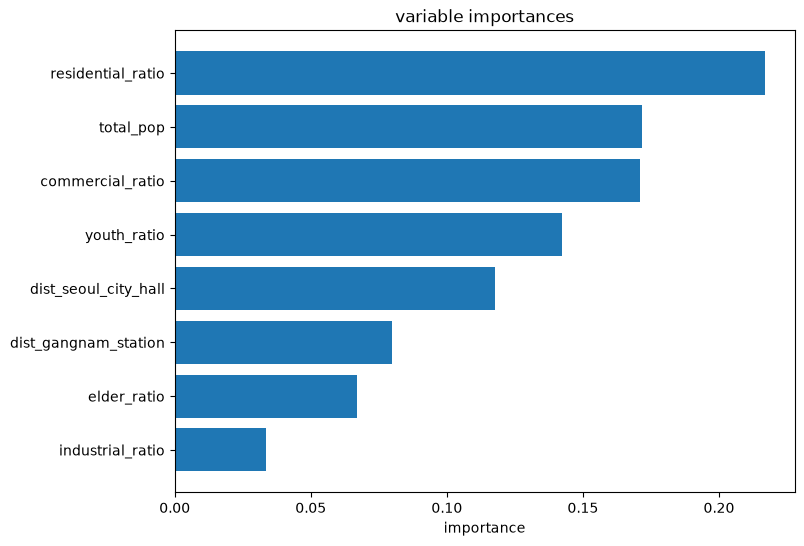

In [15]:
# 변수 중요도 시각화하기
importances_values = best_tree.feature_importances_
importances = pd.Series(importances_values, index=X_train.columns)
importances = importances.sort_values(ascending=False)
plt.figure(figsize=(8, 6))
plt.title('variable importances')
plt.barh(importances.index, importances.values)
plt.gca().invert_yaxis()   # 중요도가 큰 변수가 위로 오도록
plt.xlabel('importance')
plt.show()

### 9.1.2 Random Forest

Random Forest 모델 역시 tree 기반의 모형으로, 나무가 모여 숲이 되듯 Decision Tree를 여러 개 묶어서 만든 알고리즘입니다.\
여러 개의 tree가 예측한 값을 평균하여 최종 예측 값을 결정하는 방식으로 이루어집니다.

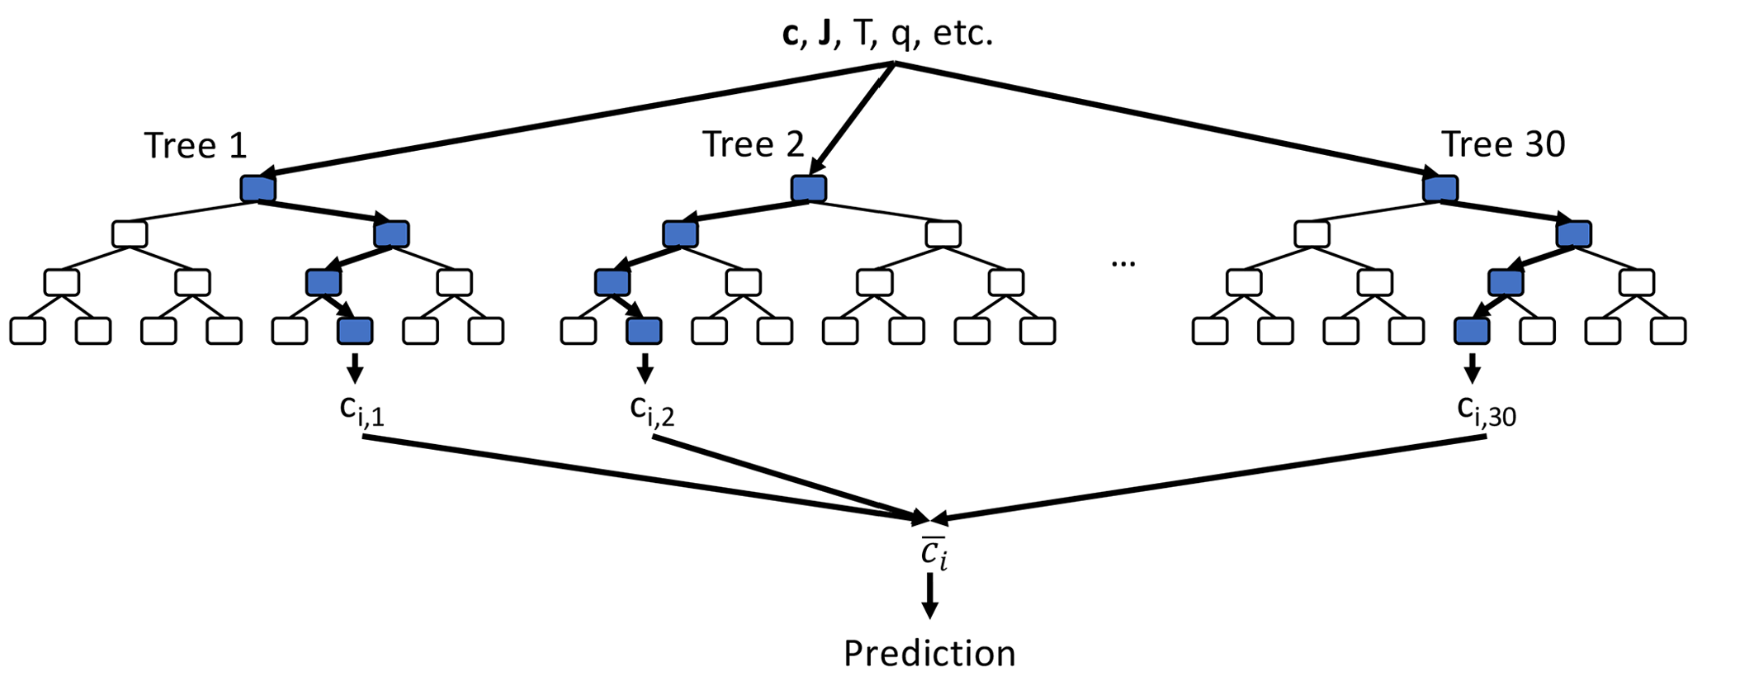

In [16]:
from sklearn.ensemble import RandomForestRegressor

forest1 = RandomForestRegressor(random_state = 1)   #random_state는 random seed 값
forest1.fit(X_train, Y_train)     # 학습 끝

RandomForestRegressor(random_state=1)

In [17]:
print_accuracy(forest1)

train RMSE: 4.044104264538243
train R-square: 0.8897243976639303
test RMSE: 10.118542283541988
test R-square: 0.24497424738066276


#### hyperparameter 조절하기

이번에도 hyperparameter tuning을 진행해보도록 하겠습니다. 기본적으로 Decision tree와 여러 hyperparameter를 공유하고, 여기에 tree의 개수를 정해주는 중요한 n_estimators 파라미터가 있습니다.기본 설정은 100개입니다.
- n_estimators : 예측에 사용하는 Decision Tree의 개수

In [18]:
# hyperparameter를 지정하고, 모델을 학습시킵니다
forest2 = RandomForestRegressor(random_state = 1, max_depth=5, min_samples_leaf = 10, n_estimators=50)
forest2.fit(X_train, Y_train)
print_accuracy(forest2)

train RMSE: 10.697562344297758
train R-square: 0.2283783526024823
test RMSE: 10.320364088799453
test R-square: 0.214554780119248


마찬가지로 random forest 모델도 GridSearchCV를 통해 hyperparameter tuning을 할 수 있습니다.

#### 변수 중요도 산출

Random Forest와 마찬가지로 변수 중요도를 산출할 수 있습니다

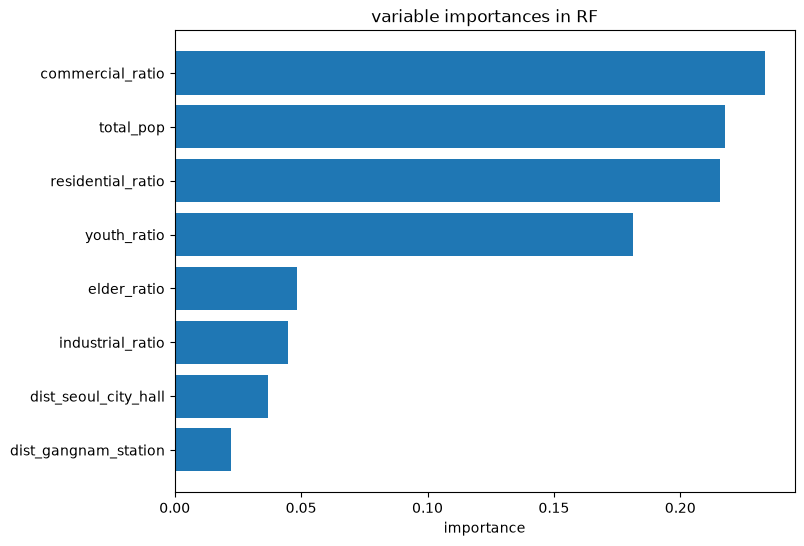

In [19]:
#변수 중요도 시각화하기
importances_values = forest2.feature_importances_
importances = pd.Series(importances_values, index=X_train.columns)
importances = importances.sort_values(ascending=False)
plt.figure(figsize=(8, 6))
plt.title('variable importances in RF')
plt.barh(importances.index, importances.values)
plt.gca().invert_yaxis()   # 중요도가 큰 변수가 위로 오도록
plt.xlabel('importance')
plt.show()

## 9.2 부스팅 Tree 계열 모델

### 9.2.1 Gradient Boosting

Gradient Boost 계열 모델은 Random Forest의 tree들을 동시에 생성하는 것이 아닌, 순차적으로 생성해가는 것이 특징입니다.\
먼저 초기의 tree를 만들고 예측값과 잔차를 계산합니다. 이를 바탕으로 새로운 tree를 점차적으로 생성하는 모형입니다. \
이러한 잔차 예측값에 learning rate를 곱하여 더하게되며, learning rate는 많은 기계학습에서 최적화 속도, 비율과 관련된 중요한 hyperparameter입니다.

<img src="https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FmLlRQ%2FbtqxpA2H9B6%2FFUbeNKDOBriocbys3V3nTk%2Fimg.png" width="700" height="500" />

<center> Gradient Boosting : 잔차 예측값들에 learning rate를 곱해 계속 더해나갑니다 <center/>

In [20]:
from sklearn.ensemble import GradientBoostingRegressor

boosting1 = GradientBoostingRegressor(random_state = 1)
boosting1.fit(X_train, Y_train)     # 학습 끝

GradientBoostingRegressor(random_state=1)

In [21]:
print_accuracy(boosting1)

train RMSE: 10.12978808565146
train R-square: 0.3081125218835027
test RMSE: 10.354863398224763
test R-square: 0.20929477021633158


여기에 몇 가지 hyperparameter를 추가해보도록 하겠습니다. 일단 기본적으로 Random Forest모델이나 Gradient Boosting 모델 모두 여러 개의 Tree를 묶어 예측하는 Ensemble 모델이기 때문에 hyperparameter를 공유합니다. 여기에 learning rate, loss가 추가됩니다.
- learning_rate : Tree를 순차적으로 생성한 후 예측에 반영하는 비율. 학습 비율 및 속도
- loss : 최적화를 진행하는 과정에서 Loss function(정답과 오답의 차이를 수치화 한 것)을 계산하는 방식
  - 'squared_error (제곱합)', 'absolute_error (절대값합)', 'huber' 등이 있음

In [22]:
boosting2 = GradientBoostingRegressor(random_state = 1, loss="squared_error",learning_rate = 0.05, max_depth=5,
                                      min_samples_leaf = 10, n_estimators=50)
boosting2.fit(X_train, Y_train)
print_accuracy(boosting2)

train RMSE: 10.353115960768191
train R-square: 0.27726862695810206
test RMSE: 10.191433014380346
test R-square: 0.2340571404767129


#### grid search, 변수 중요도

In [23]:
boosting = GradientBoostingRegressor(min_samples_leaf = 10, n_estimators=50)
parameters = {'max_depth':[5,6],'learning_rate':[0.001,0.005,0.01,0.05]}

grid_boosting = GridSearchCV(boosting, param_grid=parameters, scoring = 'r2',cv=2)
grid_boosting.fit(X_train, Y_train)
print(grid_boosting.best_params_)   #최적의 parameter 찾기, 시간이 조금 걸립니다

{'learning_rate': 0.05, 'max_depth': 6}


In [24]:
best_boosting = grid_boosting.best_estimator_
best_pred = best_boosting.predict(X_test)
print('R-square of best model:{:.4f}'.format(metrics.r2_score(Y_test, best_pred)))

R-square of best model:0.2468


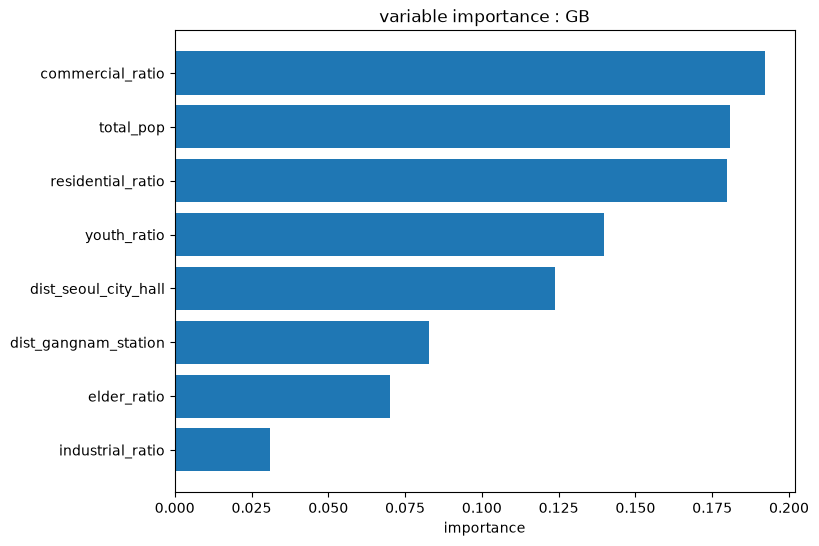

In [25]:
#변수 중요도 시각화하기
importances_values = best_boosting.feature_importances_
importances = pd.Series(importances_values, index=X_train.columns)
importances = importances.sort_values(ascending=False)
plt.figure(figsize=(8, 6))
plt.title('variable importance : GB')
plt.barh(importances.index, importances.values)
plt.gca().invert_yaxis()   # 중요도가 큰 변수가 위로 오도록
plt.xlabel('importance')
plt.show()

### 9.2.2 XGBoost

XGBoost 역시 부스팅 트리 계열 모형이며, gradient boosting의 성능을 한층 끌어올린 모델입니다. 특히 이런 발전된 Boosting 계열 모델의 경우 효율적이고 정확한 학습이 가능하여 많은 머신러닝 경진대회에서 활용하고 있습니다.

XGB 알고리즘 이해하기 : https://m.blog.naver.com/luexr/223466048770

In [26]:
!pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(random_state = 1, n_estimators = 100)
xgb_model.fit(X_train, Y_train)
print_accuracy(xgb_model)

train RMSE: 7.77855708524368
train R-square: 0.5920256706626492
test RMSE: 10.191435610654086
test R-square: 0.23405675022784744


In [28]:
# hyperparameter 변환
xgb_model2 = XGBRegressor(random_state = 1, learning_rate = 0.05, max_depth=5,
                                      max_leaves = 5, n_estimators=50)
xgb_model2.fit(X_train, Y_train)
print_accuracy(xgb_model2)

train RMSE: 11.09017893601221
train R-square: 0.1706996332835966
test RMSE: 10.57270972820827
test R-square: 0.175674981546446


### 9.2.3  LightGBM

In [29]:
!pip install lightgbm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(random_state = 1, n_estimators = 100)
lgb_model.fit(X_train, Y_train)
print_accuracy(lgb_model)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006254 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.


[LightGBM] [Info] Total Bins 2020
[LightGBM] [Info] Number of data points in the train set: 26665, number of used features: 8
[LightGBM] [Info] Start training from score 11.001613
train RMSE: 9.559774160197042
train R-square: 0.3837881922727979
test RMSE: 9.94040097611364
test R-square: 0.27132533520724156


In [31]:
lgb_model2 = LGBMRegressor(random_state = 1, n_estimators = 100, max_depth=5, learning_rate = 0.01)
lgb_model2.fit(X_train, Y_train)
print_accuracy(lgb_model2)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003045 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2020
[LightGBM] [Info] Number of data points in the train set: 26665, number of used features: 8
[LightGBM] [Info] Start training from score 11.001613
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
train RMSE: 10.90377776676199
train R-square: 0.19834273352790077
test RMSE: 10.482593140956379
test R-square: 0.18966737770446795


## 9.3 신경망 계열

마지막으로 인공신경망 계열 모형인 MLP(Multi Layer Perceptron)을 알아보도록 하겠습니다. 이 모델은 여러 출력 층을 순차적으로 붙여놓은 형태로 딥러닝 모형의 가장 기초적인 형태입니다.

<img src="https://miro.medium.com/v2/1*92lRrkeeE-vWVKrYELkN_g.jpeg" width="600" height="300" />

<center> 인공신경망 구조 (Artificial Neural Network)를 사용하고, 여러 은닉층(hidden layer)이 있는 머신러닝 모형을 특별히 딥러닝이라고 한다<center/>

input vector는 X값(독립변수), output vector는 Y값(종속변수)가 되며, 중간에 숨겨진 hidden layer가 존재한다는 것이 특징입니다.\
여기서 데이터가 많아지고, 중간 hidden layer가 많아질수록 강력한 성능을 자랑하며 CNN 부터 최근 chat-gpt까지 10년이래 큰 발전이 있었습니다\
다만 앞선 모델들에 비해 학습 시간이 길고, 변수 중요도를 볼 수 없다는 치명적 단점도 있어 목적에 맞게 잘 선택하여야 합니다!\
오늘은 scikit learn에서 제공하는 MLPRegressor를 통해 기본적인 딥러닝 모델을 학습해보도록 하겠습니다.

In [32]:
# 신경망 계열 모델은 scale의 영향을 받기 때문에 정규화가 필요합니다!
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
X_train2 = scaler.fit_transform(X_train)
X_test2 = scaler.fit_transform(X_test)

In [33]:
from sklearn.neural_network import MLPRegressor

network = MLPRegressor(hidden_layer_sizes=(20,20),batch_size=20,learning_rate_init=0.005, max_iter=100)
network.fit(X_train2, Y_train)     # 학습 끝 - 시간이 조금 걸립니다. 시간이 괜찮으면 max_iter를 조금씩 늘려보세요

MLPRegressor(batch_size=20, hidden_layer_sizes=(20, 20),
             learning_rate_init=0.005, max_iter=100)

In [34]:
Y_train_pred = network.predict(X_train2)
print('train RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred)))
print('train R-square:', metrics.r2_score(Y_train, Y_train_pred))

Y_test_pred = network.predict(X_test2)
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

train RMSE: 10.795143678788682
train R-square: 0.2142369462396928
test RMSE: 10.344865201232718
test R-square: 0.21082097286813728


MLP 모형의 대표적 hyperparameter는 다음과 같으며, 아래 hyperparameter들은 딥러닝을 하고자 하면 꼭 알아야하니 잘 익혀두시면 좋습니다.

- hidden_layer_sizes : hidden layer의 수와 neuron(그림에서 동그라미, 한 layer에서 출력값 node의 개수)의 수
- activation : 다음 layer로 출력 전 통과하는 활성함수의 종류. relu가 대중적이다.
- batch_size : 한 번의 training에서 학습하는 dataset 묶음의 개수
- learning_rate_init : 초기 learning rate (학습 속도, 안정성에 영향)
- max_iter : 학습 반복횟수. 크게하면 시간이 꽤 많이 증가하지만, 성능은 많이 향상됨

In [35]:
network2 = MLPRegressor(hidden_layer_sizes=(16,32,32,64,32,8),batch_size=20,learning_rate_init=0.01, max_iter=300)  # 복잡한 모델은 다음과 같습니다.
network2.fit(X_train, Y_train)

MLPRegressor(batch_size=20, hidden_layer_sizes=(16, 32, 32, 64, 32, 8),
             learning_rate_init=0.01, max_iter=300)

In [36]:
Y_train_pred = network2.predict(X_train2)
print('train RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred)))
print('train R-square:', metrics.r2_score(Y_train, Y_train_pred))

Y_test_pred = network2.predict(X_test2)
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

train RMSE: 12.179636590597433
train R-square: -0.00023814130352017848
test RMSE: 11.645014057212194
test R-square: -1.3579457900814162e-05


c:\Users\leeja\Dropbox\0_Classes\5_스마트도시데이터분석\.venv2\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MLPRegressor was fitted with feature names
  warnings.warn(
c:\Users\leeja\Dropbox\0_Classes\5_스마트도시데이터분석\.venv2\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MLPRegressor was fitted with feature names
  warnings.warn(


딥러닝은 이미지 분류, 시계열 분석 등 다양한 분야에 응용될 수 있습니다. 딥러닝은 특히 다른 머신러닝 알고리즘에 비해 큰 데이터셋에 유리합니다 전문적인 딥러닝 모델 개발은 tensorflow나, pytorch등 라이브러리를 이용하여야 합니다.

### 9.4 교차검증으로 최적 모형 선택하기

지금까지는 모형마다 test set 성능을 보면서 비교했습니다. 하지만 **test set을 보고 모형을 고르면, test set이 사실상 검증용 데이터가 되어버립니다.** 그러면 최종 성능이 실제보다 좋게(낙관적으로) 나오게 됩니다.

올바른 절차는 다음과 같습니다.
1. 데이터를 training set과 test set으로 나눈다 (앞에서 이미 7:3으로 나눔)
2. **training set 안에서만** 5-fold cross validation으로 각 모형의 hyperparameter를 튜닝한다
3. 각 모형의 **CV 점수(5개 fold 평균)** 를 비교해서 최종 모형을 고른다
4. 고른 모형 **하나만** test set에 적용해서 최종 성능을 보고한다 (test set은 마지막에 단 한 번!)

#### 공정한 비교를 위한 준비

- **모든 모형이 똑같은 fold로 평가되도록** KFold 객체를 하나 만들어 같이 사용합니다.
- **평가 지표도 하나로 고정**합니다. 여기서는 RMSE를 사용합니다. (sklearn은 점수가 클수록 좋은 것으로 취급하기 때문에 `neg_root_mean_squared_error`처럼 음수 RMSE를 사용합니다)

In [37]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# shuffle=True, random_state를 고정하여 모든 모형이 같은 5개 fold로 평가되도록 합니다
cv = KFold(n_splits=5, shuffle=True, random_state=42)

#### MLP는 Pipeline으로 스케일링까지 묶기

MLP처럼 scale에 민감한 모형은 정규화가 필요합니다. 그런데 cross validation에서는 **각 fold마다 그 fold의 학습 부분으로만** scaler를 학습해야 검증 데이터의 정보가 새어 들어가지 않습니다(data leakage).\
`Pipeline`으로 scaler와 모형을 하나로 묶으면 GridSearchCV가 이 과정을 자동으로 처리해줍니다. Pipeline 안의 hyperparameter는 `단계이름__파라미터` 형식으로 지정합니다.

> 참고: 앞의 9.3처럼 직접 정규화할 때도 test set에는 `fit_transform`이 아니라, training set으로 학습한 scaler의 `transform`만 적용해야 합니다.

#### 모형별 탐색할 hyperparameter 정의

각 모형에 비슷한 정도의 탐색 예산(조합 수)을 주어야 공정한 비교가 됩니다. 부스팅 모형은 `n_estimators`와 `learning_rate`가 서로 맞물려 있으므로(learning rate가 작으면 tree가 많이 필요) 함께 튜닝합니다.

In [38]:
models = {
    'CART': (DecisionTreeRegressor(random_state=1),
             {'max_depth': [3, 5, 7, 9, 12], 'min_samples_leaf': [5, 10, 20, 50]}),
    'RF':   (RandomForestRegressor(random_state=1),
             {'n_estimators': [200], 'max_depth': [5, 10, None],
              'min_samples_leaf': [5, 10, 20], 'max_features': [0.33, 0.66, 1.0]}),
    'XGB':  (XGBRegressor(random_state=1),
             {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1],
              'max_depth': [3, 5, 7], 'subsample': [0.8, 1.0]}),
    'LGBM': (LGBMRegressor(random_state=1, verbose=-1),
             {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1],
              'num_leaves': [15, 31, 63], 'min_child_samples': [20, 50]}),
    'MLP':  (Pipeline([('scaler', StandardScaler()),
                       ('mlp', MLPRegressor(max_iter=500, early_stopping=True, random_state=1))]),
             {'mlp__hidden_layer_sizes': [(32,), (64, 32), (64, 64)],
              'mlp__alpha': [1e-4, 1e-3, 1e-2], 'mlp__learning_rate_init': [1e-3, 1e-2]}),
}

In [40]:
# 모형별로 5-fold CV grid search 진행 (시간이 꽤 걸립니다)
results = {}
for name, (est, grid) in models.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, Y_train)
    results[name] = {'cv_rmse': -gs.best_score_,
                     'cv_std': gs.cv_results_['std_test_score'][gs.best_index_],
                     'params': gs.best_params_,
                     'model': gs.best_estimator_}
    print(name, '완료')

CART 완료
RF 완료
XGB 완료
LGBM 완료
MLP 완료


In [41]:
# CV RMSE가 작은 순서로 정렬 (test set은 아직 사용하지 않았습니다!)
summary = pd.DataFrame(results).T[['cv_rmse', 'cv_std', 'params']].sort_values('cv_rmse')
summary

,cv_rmse,cv_std,params
RF,10.409552,0.696038,"{'max_depth': None, 'max_features': 0.66, 'min..."
LGBM,10.526649,0.67646,"{'learning_rate': 0.03, 'min_child_samples': 5..."
XGB,10.661609,0.737741,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
MLP,10.810304,0.730556,"{'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes..."
CART,10.851301,0.655493,"{'max_depth': 9, 'min_samples_leaf': 20}"


#### 결과 해석 시 주의할 점

- **차이가 작으면 동률로 봅니다.** CV RMSE 차이가 fold 간 표준편차(`cv_std`)보다 작다면 사실상 같은 성능입니다. 이때는 더 단순하거나 해석이 쉬운 모형을 고르는 것이 좋습니다 (one-standard-error rule).
- **최적값이 탐색 범위 끝에 걸렸는지 확인합니다.** 예를 들어 9.2.1의 GBM grid search 결과 `{'learning_rate': 0.05, 'max_depth': 6}`은 두 값 모두 탐색 범위의 최댓값이었습니다. 이런 경우 범위를 넓혀서 다시 탐색해야 합니다.

In [42]:
# CV로 고른 최종 모형을 test set에 단 한 번 적용합니다
best_name = summary.index[0]
final_model = results[best_name]['model']
print('최종 선택 모형:', best_name)
print_accuracy(final_model)

최종 선택 모형: RF
train RMSE: 8.29757638778915
train R-square: 0.5357656530639325
test RMSE: 9.772177538092723
test R-square: 0.29577966719454896


#### (심화) 공간 자료의 교차검증

우리 데이터는 격자(grid) 단위 공간 자료입니다. 가까운 격자끼리는 값이 비슷한 **공간 자기상관**이 있기 때문에, 랜덤으로 fold를 나누면 검증 격자의 바로 옆 격자가 학습에 들어가서 성능이 부풀려질 수 있습니다.\
모형을 **새로운 지역에 적용**하는 것이 목적이라면, 자치구처럼 지역 단위로 fold를 나누는 공간 교차검증(`GroupKFold`)이 더 현실적인 평가입니다.

```python
from sklearn.model_selection import GroupKFold
cv_spatial = GroupKFold(n_splits=5)
gs = GridSearchCV(est, grid, cv=cv_spatial, scoring='neg_root_mean_squared_error')
gs.fit(X_train, Y_train, groups=gu_train)   # gu_train: training set 격자의 자치구 이름
```

랜덤 CV와 공간 CV의 점수를 비교해보면 공간 자기상관이 성능 평가에 얼마나 영향을 주는지 확인할 수 있습니다.

같은 이유로, 다음 절에서 관악구에 예측 모형을 적용할 때 관악구 격자가 이미 학습 데이터에 포함되어 있다면 "새로운 지역 예측"이 아니라는 점에 유의해야 합니다. 엄밀하게 하려면 관악구를 제외하고 학습한 모형으로 예측해야 합니다.

### 9.5 모델을 활용하여 예측값 매핑하기

이렇게 만든 모델은 어떻게 사용할까요? 만약 어떤 도시에 심정지를 대비한 비상벨을 새로 도입하고 싶은데, 최적의 위치에 설치하려면 어떻게 해야할까요? 서울시의 심정지 신고건수를 바탕으로 학습한 모형이 있다면, 새로운 도시에서 심정지 사고가 많이 들어올 곳을 파악할 수 있지 않을까요? 이처럼 예측 모형은 기존 현상을 예측하여 새로운 정책을 도입하고 싶을 때 활용할 수 있습니다.\
관악구를 대상으로 앞서 학습한 예측 모형을 적용해보고 이를 시각화해보도록 하겠습니다.

머신러닝을 활용하면, 제한된 데이터, 지역을 바탕으로 패턴을 학습 => 전체 지역, 타  지역 등으로 확산이 가능합니다.

In [43]:
border_geojson = gpd.read_file('data/서울구경계.geojson')
border_gw = border_geojson[border_geojson['SIG_KOR_NM']=='관악구']
border_gw = border_gw.to_crs(pop_grid.crs)   # 공간조인 전에 두 데이터의 좌표계를 반드시 맞춰줍니다

# 관악구와 겹치는 격자만 남깁니다 (how='inner')
pop_grid_gw = gpd.sjoin(pop_grid, border_gw[['SIG_KOR_NM','geometry']], how='inner')
print(len(pop_grid_gw), '개 격자')

1497 개 격자


#### 관악구를 제외하고 학습하기

앞에서 학습한 모형은 관악구 격자 일부가 이미 training set에 들어가 있습니다. 그대로 관악구를 예측하면 "새로운 지역 예측"이 아니라 이미 본 데이터를 다시 맞히는 셈이 됩니다.\
그래서 **관악구를 뺀 나머지 지역으로만 모형을 다시 학습**하고, 관악구는 처음 보는 지역으로 두고 예측하겠습니다. 모형과 hyperparameter는 9.4에서 교차검증으로 고른 최종 모형(`final_model`)을 그대로 사용합니다.

`clone`은 hyperparameter 설정만 복사하고 학습 결과는 비운 새 모형을 만들어줍니다.

In [44]:
from sklearn.base import clone

features = X.columns   # 앞에서 사용한 8개 독립변수
is_gw = pop_grid.index.isin(pop_grid_gw.index)

# 9.4에서 고른 모형과 같은 hyperparameter로, 관악구를 제외한 나머지 서울 데이터만 학습합니다
model_gw = clone(final_model)
model_gw.fit(pop_grid.loc[~is_gw, features], pop_grid.loc[~is_gw, 'emergency_no'])

RandomForestRegressor(max_features=0.66, min_samples_leaf=5, n_estimators=200,
                      random_state=1)

In [45]:
# 관악구는 학습에 쓰지 않았으므로, 이 성능이 "새로운 지역"에 대한 예측력입니다
X_gw = pop_grid_gw[features]
Y_gw_pred = model_gw.predict(X_gw)

print('관악구 RMSE:', np.sqrt(metrics.mean_squared_error(pop_grid_gw['emergency_no'], Y_gw_pred)))
print('관악구 R-square:', metrics.r2_score(pop_grid_gw['emergency_no'], Y_gw_pred))

관악구 RMSE: 12.286437547225571
관악구 R-square: 0.15401836139801195


In [46]:
# 원래 데이터에 신고건수 예측 데이터를 넣어주도록 하겠습니다.
pop_grid_gw['emergency_no_pred'] = Y_gw_pred
pop_grid_gw.head(5)

,격자고유번호,total_pop,elder_ratio,youth_ratio,industrial_ratio,commercial_ratio,residential_ratio,dist_seoul_city_hall,dist_gangnam_station,emergency_no,geometry,index_right,SIG_KOR_NM,emergency_no_pred
1043,다사470428,259.0,0.142857,0.084942,0.144176,0.806284,0.048977,11486.614826,11303.657435,42.0,"MULTIPOLYGON (((126.90052 37.48292, 126.90052 ...",20,관악구,27.065259
1157,다사547409,156.0,0.160256,0.096154,0.000000,0.000000,0.434777,11123.985656,4913.988414,8.0,"MULTIPOLYGON (((126.98773 37.4662, 126.98773 3...",20,관악구,4.560451
1158,다사547407,156.0,0.160256,0.096154,0.000000,0.000000,0.000000,11323.458307,5056.520635,4.0,"MULTIPOLYGON (((126.98774 37.4644, 126.98774 3...",20,관악구,2.054278
1341,다사534420,348.0,0.158046,0.051724,0.000000,0.000000,1.000000,10005.914134,5342.472729,16.0,"MULTIPOLYGON (((126.97296 37.47605, 126.97296 ...",20,관악구,15.328629
1365,다사531420,385.0,0.142857,0.059740,0.000000,0.000000,1.000000,10024.950242,5613.369011,7.0,"MULTIPOLYGON (((126.96957 37.47604, 126.96956 ...",20,관악구,15.826489


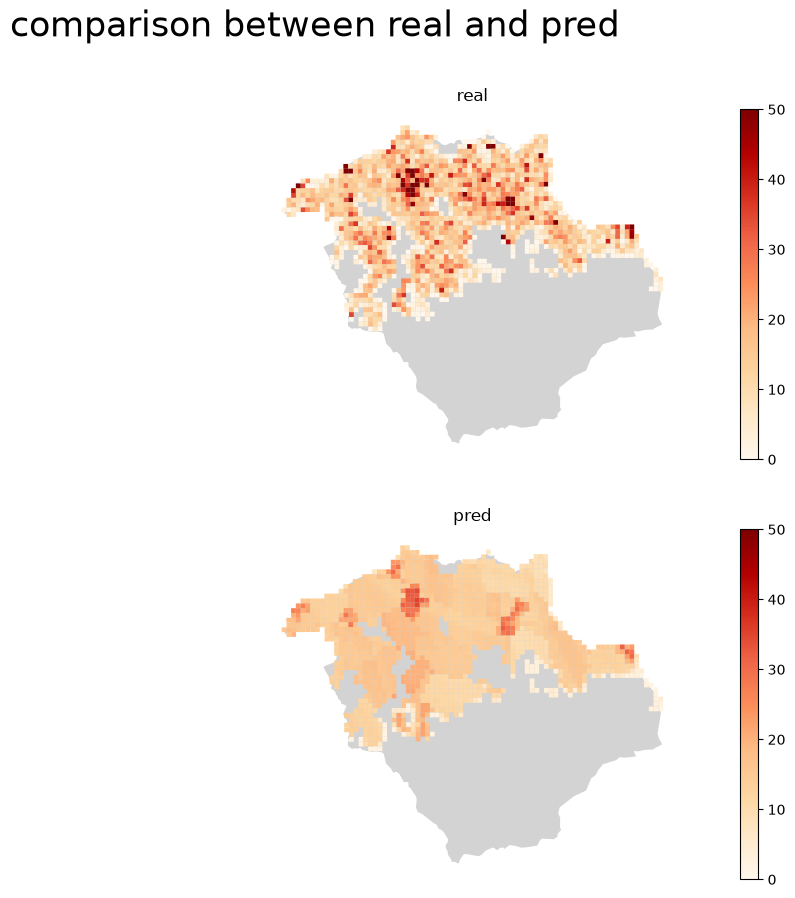

In [47]:
# 실제값과 예측값을 비교하여 plot해보도록 하겠습니다.
fig = plt.figure(figsize=(15,10))
ax1 = fig.add_subplot(2,1,1)
ax2 = fig.add_subplot(2,1,2)
border_gw.plot(ax=ax1,color = 'lightgray',linewidth=0)
border_gw.plot(ax=ax2,color = 'lightgray',linewidth=0)
pop_grid_gw.plot(ax=ax1,column = 'emergency_no',cmap = 'OrRd',vmin=0, vmax =50,linewidth=0,legend=True)
pop_grid_gw.plot(ax=ax2,column = 'emergency_no_pred',cmap = 'OrRd',vmin=0, vmax =50,linewidth=0,legend=True)
fig.suptitle('comparison between real and pred', fontsize = 25)
ax1.set_title("real")
ax2.set_title("pred")
ax1.set_axis_off()
ax2.set_axis_off()
plt.show()

관악구 예측의 R-square를 9.4의 test set R-square와 비교해보세요. 관악구처럼 **학습에 전혀 쓰지 않은 지역**을 예측할 때는 성능이 눈에 띄게 낮아집니다.랜덤으로 나눈 test set에는 학습 격자의 바로 옆 격자들이 섞여 있어 예측이 상대적으로 쉽기 때문입니다(공간 자기상관). 그래서 모형을 새로운 지역에 적용하려 한다면, 랜덤 test set 성능보다 이렇게 **지역 단위로 떼어놓고 평가한 성능**을 기대하는 것이 현실적입니다.

예측 지도를 보면 전체적인 공간 패턴(신고가 많은 곳과 적은 곳)은 잡아내지만, 실제값보다 훨씬 매끄럽고 극단값은 잘 맞히지 못하는 것도 확인할 수 있습니다.

### 9.6 최종 모형(Random Forest) 저장하고 다른 곳에서 불러오기

9.4의 교차검증에서 CV RMSE가 가장 낮았던 **Random Forest(RF)** 가 최종 모형으로 선택되었습니다. 이 모형을 파일로 저장해두면 다른 노트북이나 스크립트에서 다시 학습하지 않고 바로 예측에 쓸 수 있습니다. scikit-learn 모형은 `joblib`으로 저장하는 것이 일반적입니다.

- **전체 데이터로 다시 학습하기**: test set 평가는 9.4에서 이미 끝났으므로, 실제로 쓸 모형은 같은 hyperparameter로 training set과 test set을 합친 전체 데이터를 학습시키는 것이 좋습니다. 데이터가 많을수록 예측이 안정적이기 때문입니다.
- **모형만 저장하지 말고 정보도 함께 저장하기**: 어떤 변수를 어떤 순서로 넣어야 하는지(`features`), hyperparameter와 CV 성능이 어땠는지를 같이 저장해두어야 나중에 헷갈리지 않습니다.
- **RF는 정규화가 필요 없습니다**: Tree 계열 모형이라 scale의 영향을 받지 않으므로, 새 데이터도 원래 단위 그대로 넣으면 됩니다.
- **파일 크기**: RF는 깊은 tree 200개를 통째로 저장하므로 파일이 꽤 커질 수 있습니다. `compress` 옵션으로 압축해서 저장합니다.

> 주의: 불러오는 쪽에도 scikit-learn이 설치되어 있어야 하며, 버전이 많이 다르면 불러오기가 실패하거나 경고가 날 수 있습니다. 그래서 학습할 때의 버전도 같이 기록해둡니다.

In [48]:
import joblib
import os
from pathlib import Path
from sklearn.base import clone

print('최종 선택 모형:', best_name)   # RF

# 9.4에서 고른 RF와 같은 hyperparameter로, 전체 데이터(training + test)를 다시 학습합니다
final_rf = clone(final_model)
final_rf.fit(X, Y)
print(final_rf)

# 모형과 함께 사용에 필요한 정보를 하나의 딕셔너리로 묶어 저장합니다
bundle = {
    'model': final_rf,
    'features': list(X.columns),          # 예측할 때 넣어야 하는 독립변수와 순서
    'target': 'emergency_no',
    'model_name': best_name,
    'params': results[best_name]['params'],
    'cv_rmse': results[best_name]['cv_rmse'],
    'sklearn_version': sklearn.__version__,
}

Path('model').mkdir(exist_ok=True)
save_path = 'model/emergency_rf_model.joblib'
joblib.dump(bundle, save_path, compress=3)   # compress: 0(압축 안 함)~9(최대 압축)
print('저장 완료:', save_path, f'({os.path.getsize(save_path)/1024**2:.1f} MB)')

최종 선택 모형: RF
RandomForestRegressor(max_features=0.66, min_samples_leaf=5, n_estimators=200,
                      random_state=1)
저장 완료: model/emergency_rf_model.joblib (28.7 MB)


#### 저장한 RF 모형 불러와서 예측하기

아래 코드는 다른 노트북이나 파이썬 스크립트에 그대로 붙여 넣어 사용할 수 있습니다(앞의 변수들이 없어도 동작합니다). 새 데이터는 저장해둔 `features`와 같은 변수명을 가지고 있어야 하며, 이름으로 열을 골라 넣으면 순서도 자동으로 맞춰집니다.

예시로 같은 격자 데이터를 다시 불러와 예측해보겠습니다. 저장한 모형은 서울 전체(관악구 포함)로 학습했으므로, 여기서의 예측은 성능 평가가 아니라 **사용법 예시**입니다. 실제로는 같은 변수를 만든 새 지역의 데이터를 넣으면 됩니다.

In [49]:
import joblib
import geopandas as gpd

bundle = joblib.load('model/emergency_rf_model.joblib')
rf = bundle['model']
print('모형:', bundle['model_name'], '| hyperparameter:', bundle['params'])
print('필요한 변수:', bundle['features'])

# 새 데이터 불러오기 (학습 때와 같은 전처리: 고령층·유소년층 비율이 NaN인 격자 제외)
new_grid = gpd.read_file('data/pop_grid_ml.geojson', encoding='utf-8')
new_grid = new_grid[new_grid['elder_ratio'].notna() & new_grid['youth_ratio'].notna()]

new_grid['emergency_no_pred'] = rf.predict(new_grid[bundle['features']])
new_grid[['emergency_no', 'emergency_no_pred']].head()

모형: RF | hyperparameter: {'max_depth': None, 'max_features': 0.66, 'min_samples_leaf': 5, 'n_estimators': 200}
필요한 변수: ['total_pop', 'elder_ratio', 'youth_ratio', 'industrial_ratio', 'commercial_ratio', 'residential_ratio', 'dist_seoul_city_hall', 'dist_gangnam_station']


,emergency_no,emergency_no_pred
0,0.0,0.819261
1,0.0,1.423126
2,2.0,4.005935
3,46.0,28.430802
4,16.0,12.410769


In [50]:
new_grid

,격자고유번호,total_pop,elder_ratio,youth_ratio,industrial_ratio,commercial_ratio,residential_ratio,dist_seoul_city_hall,dist_gangnam_station,emergency_no,geometry,emergency_no_pred
0,다사383536,191.0,0.193717,0.083770,0.0,0.000000,0.021743,15668.029228,21940.402533,0.0,"MULTIPOLYGON (((126.80122 37.57972, 126.80121 ...",0.819261
1,다사385537,191.0,0.193717,0.083770,0.0,0.000000,0.000000,15479.796763,21801.883085,0.0,"MULTIPOLYGON (((126.80348 37.58063, 126.80347 ...",1.423126
2,다사386529,319.0,0.147335,0.144201,0.0,0.000000,0.195661,15312.335197,21379.365808,2.0,"MULTIPOLYGON (((126.80467 37.57343, 126.80467 ...",4.005935
3,다사387525,191.0,0.193717,0.083770,0.0,0.000000,1.000000,15193.939852,21130.315213,46.0,"MULTIPOLYGON (((126.80584 37.56983, 126.80583 ...",28.430802
4,다사387524,191.0,0.193717,0.083770,0.0,0.000000,0.569658,15190.939201,21091.960089,16.0,"MULTIPOLYGON (((126.80585 37.56893, 126.80584 ...",12.410769
...,...,...,...,...,...,...,...,...,...,...,...,...
38089,다사491438,283.0,0.144876,0.113074,0.0,0.683306,0.316694,9489.198938,9113.276018,23.0,"MULTIPOLYGON (((126.92421 37.49205, 126.9242 3...",25.850843
38090,다사491434,402.0,0.084577,0.024876,0.0,0.000000,1.000000,9836.676206,9146.258109,21.0,"MULTIPOLYGON (((126.92423 37.48844, 126.92423 ...",19.612604
38091,다사491517,229.0,0.148472,0.056769,0.0,0.000000,1.000000,4794.546516,11693.058073,11.0,"MULTIPOLYGON (((126.92366 37.56325, 126.92365 ...",11.427577
38092,다사491513,142.0,0.133803,0.042254,0.0,0.000000,1.000000,4835.594956,11445.953202,41.0,"MULTIPOLYGON (((126.92369 37.55965, 126.92368 ...",16.259669


#### 웹 앱용으로 저장하기: ONNX + app_meta.json

이번에는 이 모형으로 **지역(셀)의 특성을 입력하면 신고건수를 예측해주는 웹 앱**을 만들어 GitHub에 올리고 Cloudflare Pages로 배포한다고 해보겠습니다.

그런데 앞에서 저장한 joblib 파일은 파이썬과 scikit-learn이 있어야만 쓸 수 있습니다. Cloudflare Pages는 HTML·JavaScript 파일을 그대로 보여주는 곳이라 scikit-learn을 실행할 수 없습니다. 그래서 웹 앱용으로는 다음 두 파일을 따로 만듭니다.

- **`emergency_rf.onnx`**: ONNX는 머신러닝 모형을 저장하는 표준 형식입니다. scikit-learn 없이도 브라우저에서 `onnxruntime-web`으로 예측할 수 있어서, 서버 없이 정적 사이트로 배포할 수 있습니다.
- **`app_meta.json`**: 입력 화면을 만드는 데 필요한 정보입니다. 변수 이름과 순서, 슬라이더 범위, 자치구별 기본값이 들어갑니다. 모형 파일에는 이런 정보가 없기 때문에 따로 저장해야 합니다.

In [51]:
!pip install skl2onnx onnxruntime


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### 모형 가볍게 만들기

Cloudflare Pages는 **파일 하나가 25MiB를 넘으면 올릴 수 없습니다.** 최종 RF(tree 200개, 깊이 제한 없음)를 ONNX로 바꾸면 약 56MB라 그대로는 배포할 수 없습니다.

그래서 9.4에서 고른 hyperparameter는 유지하고 **tree 개수(`n_estimators`)와 깊이(`max_depth`, `min_samples_leaf`)만 줄인 경량 RF**를 만들어, 같은 fold로 CV 성능을 비교해보겠습니다. 9.4에서 배운 것처럼 CV RMSE 차이가 fold 간 표준편차보다 작으면 사실상 같은 성능으로 봅니다.

In [52]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# 9.4에서 고른 RF의 hyperparameter에서 tree 개수와 깊이만 줄입니다
light_params = dict(results[best_name]['params'])
light_params.update(n_estimators=100, max_depth=12, min_samples_leaf=10)
light_rf = RandomForestRegressor(random_state=1, **light_params)

# 9.4와 같은 fold(cv)와 같은 training set으로 평가합니다
light_scores = -cross_val_score(light_rf, X_train, Y_train, cv=cv,
                                scoring='neg_root_mean_squared_error', n_jobs=-1)

print('경량 RF hyperparameter:', light_params)
print(f"최종 RF  CV RMSE: {results[best_name]['cv_rmse']:.3f} (fold 간 std {results[best_name]['cv_std']:.3f})")
print(f"경량 RF  CV RMSE: {light_scores.mean():.3f} (fold 간 std {light_scores.std():.3f})")

경량 RF hyperparameter: {'max_depth': 12, 'max_features': 0.66, 'min_samples_leaf': 10, 'n_estimators': 100}
최종 RF  CV RMSE: 10.410 (fold 간 std 0.696)
경량 RF  CV RMSE: 10.507 (fold 간 std 0.700)


CV RMSE가 조금 늘었지만 그 차이가 fold 간 표준편차보다 훨씬 작으므로 사실상 같은 성능입니다. 경량 RF를 전체 데이터(training + test)로 다시 학습해 ONNX로 저장하겠습니다.

- `FloatTensorType([None, 8])`: 입력은 변수 8개짜리 행을 여러 개 받을 수 있다는 뜻입니다. ONNX는 float32로 계산하므로, 앱에서도 **같은 변수 순서의 float32 배열**로 넣어야 합니다.
- 저장한 뒤에는 ONNX 예측값과 scikit-learn 예측값이 같은지 꼭 확인합니다.

In [53]:
from skl2onnx import to_onnx
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort

features = list(X.columns)    # 이 순서가 곧 ONNX 입력 순서입니다
light_rf.fit(X, Y)            # 전체 데이터로 학습

onx = to_onnx(light_rf,
              initial_types=[('input', FloatTensorType([None, len(features)]))],
              target_opset={'': 17, 'ai.onnx.ml': 3})   # 브라우저용 onnxruntime-web이 지원하는 버전

Path('model').mkdir(exist_ok=True)
onnx_path = 'model/emergency_rf.onnx'
with open(onnx_path, 'wb') as f:
    f.write(onx.SerializeToString())
print('저장 완료:', onnx_path, f'({os.path.getsize(onnx_path)/1024**2:.1f} MB)')

# ONNX로 예측해서 scikit-learn 예측과 비교합니다
sess = ort.InferenceSession(onnx_path)
onnx_pred = sess.run(None, {'input': X.values.astype(np.float32)})[0].ravel()
print('scikit-learn과의 최대 차이:', np.abs(onnx_pred - light_rf.predict(X)).max())

저장 완료: model/emergency_rf.onnx (5.4 MB)
scikit-learn과의 최대 차이: 7.4318088962854745e-06


#### 입력 화면 정보 저장하기 (app_meta.json)

앱은 **자치구를 먼저 고르고**, 그 구의 중앙값으로 슬라이더 초기값을 채운 뒤 사용자가 값을 바꾸는 방식으로 만들 예정입니다. 이를 위해 다음 정보를 저장합니다.

- **`features`**: 변수별 이름(라벨), 단위, 슬라이더 범위(`min`, `max`, `step`)와 형식(`type`). 연속변수는 `continuous`(슬라이더), 범주형 변수는 `categorical`(드롭다운, `options` 목록 포함)로 표시합니다. 지금 모형의 8개 변수는 모두 연속변수입니다.
- **`range_by_region`**: 서울시청·강남역까지 거리는 격자의 위치로 정해지는 값입니다. 관악구를 골랐는데 시청까지 거리를 2km로 둘 수는 없으므로, 이 표시가 있는 변수는 앱에서 선택한 자치구의 범위로 슬라이더를 좁힙니다.
- **`regions`**: 자치구별 격자 수, 실제 평균 신고건수, 변수별 중앙값(기본값)과 범위.
- **`constraints`**: 변수끼리 지켜야 하는 조건. 용도지역 비율 3개는 합이 1을 넘을 수 없으므로 앱에서 이를 제한하게 합니다.

슬라이더 범위는 **학습 데이터의 범위 안으로** 정합니다. RF는 학습 범위를 벗어난 값이 들어오면 끝값과 같은 예측을 내기 때문에, 범위 밖 입력은 의미가 없습니다.

먼저 데이터에는 자치구 정보가 없으므로, 격자 중심점이 들어가는 자치구를 공간조인으로 붙입니다.

In [54]:
# 격자 중심점이 들어가는 자치구를 붙입니다 (중심점은 미터 좌표계 EPSG:5179에서 계산)
gu_border = gpd.read_file('data/서울구경계.geojson').to_crs(5179)[['SIG_KOR_NM', 'geometry']]
grid_pts = pop_grid.to_crs(5179)
grid_pts['geometry'] = grid_pts.geometry.centroid

# 중심점이 경계선 밖에 살짝 걸친 격자도 있으므로, 가장 가까운 구를 붙이는 sjoin_nearest를 사용합니다
grid_gu = gpd.sjoin_nearest(grid_pts, gu_border, how='left')
grid_gu = grid_gu[~grid_gu.index.duplicated()]   # 두 구 경계에 정확히 걸린 경우 하나만 남김

print('자치구 수:', grid_gu['SIG_KOR_NM'].nunique(), '| 격자 수:', len(grid_gu))
grid_gu['SIG_KOR_NM'].value_counts().sort_index()

자치구 수: 25 | 격자 수: 38094


SIG_KOR_NM
강남구     2703
강동구     1502
강북구     1152
강서구     2019
관악구     1419
광진구     1158
구로구     1556
금천구      888
노원구     1739
도봉구     1160
동대문구    1281
동작구     1319
마포구     1448
서대문구    1349
서초구     2402
성동구     1149
성북구     1756
송파구     2345
양천구     1454
영등포구    1591
용산구     1271
은평구     1793
종로구     1484
중구       879
중랑구     1277
Name: count, dtype: int64

In [55]:
import json
import math
from datetime import date

# 변수별 라벨, 단위, 슬라이더 간격
feature_info = {
    'total_pop':            ('거주인구', '명', 1),
    'elder_ratio':          ('고령인구 비율 (65세 이상)', '비율', 0.005),
    'youth_ratio':          ('유소년인구 비율 (0~14세)', '비율', 0.005),
    'industrial_ratio':     ('공업지역 비율', '비율', 0.01),
    'commercial_ratio':     ('상업지역 비율', '비율', 0.01),
    'residential_ratio':    ('주거지역 비율', '비율', 0.01),
    'dist_seoul_city_hall': ('서울시청까지 거리', 'm', 10),
    'dist_gangnam_station': ('강남역까지 거리', 'm', 10),
}

def decimals(step):
    return max(0, -int(math.floor(math.log10(step))))

def snap(v, step, how=round):   # 값을 슬라이더 간격에 맞춰 반올림(또는 내림·올림)
    return round(how(v / step) * step, decimals(step))

def region_info(name, df):
    return {
        'name': name,
        'n_cells': int(len(df)),
        'observed_mean': round(float(df['emergency_no'].mean()), 2),
        'defaults': {f: snap(df[f].median(), feature_info[f][2]) for f in features},
        'ranges': {f: [snap(df[f].min(), feature_info[f][2], math.floor),
                       snap(df[f].max(), feature_info[f][2], math.ceil)] for f in features},
    }

app_meta = {
    'model': {
        'file': 'emergency_rf.onnx',
        'input_name': sess.get_inputs()[0].name,
        'output_name': sess.get_outputs()[0].name,
        'input_dtype': 'float32',
        'algorithm': 'RandomForestRegressor',
        'params': light_params,
        'cv_rmse': round(float(light_scores.mean()), 3),
        'target': 'emergency_no',
        'target_label': '119 응급출동 건수 (격자당, 2020년)',
        'n_train': int(len(X)),
        'sklearn_version': sklearn.__version__,
        'created': date.today().isoformat(),
    },
    # 순서가 ONNX 입력 순서와 같아야 합니다
    'features': [
        {'name': f, 'label': feature_info[f][0], 'unit': feature_info[f][1], 'type': 'continuous',
         'min': snap(X[f].min(), feature_info[f][2], math.floor),
         'max': snap(X[f].max(), feature_info[f][2], math.ceil),
         'step': feature_info[f][2],
         # 거리 변수는 위치로 정해지므로, 앱에서 슬라이더 범위를 선택한 자치구의 범위로 좁힙니다
         'range_by_region': f in ['dist_seoul_city_hall', 'dist_gangnam_station']}
        for f in features
    ],
    'constraints': [
        {'type': 'max_sum', 'label': '용도지역 비율의 합',
         'features': ['industrial_ratio', 'commercial_ratio', 'residential_ratio'], 'max': 1}
    ],
    # '서울 전체'를 맨 앞에 두고, 자치구는 가나다순
    'regions': [region_info('서울 전체', grid_gu)] +
               [region_info(name, df) for name, df in grid_gu.groupby('SIG_KOR_NM')],
}

meta_path = 'model/app_meta.json'
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(app_meta, f, ensure_ascii=False, indent=2)
print('저장 완료:', meta_path)
pd.DataFrame(app_meta['features']).set_index('name')

저장 완료: model/app_meta.json


,label,unit,type,min,max,step
name,,,,,,
total_pop,거주인구,명,continuous,21.000,539.00,1.000
elder_ratio,고령인구 비율 (65세 이상),비율,continuous,0.045,0.30,0.005
youth_ratio,유소년인구 비율 (0~14세),비율,continuous,0.000,0.25,0.005
industrial_ratio,공업지역 비율,비율,continuous,0.000,1.00,0.010
commercial_ratio,상업지역 비율,비율,continuous,0.000,1.00,0.010
residential_ratio,주거지역 비율,비율,continuous,0.000,1.00,0.010
dist_seoul_city_hall,서울시청까지 거리,m,continuous,10.000,18180.00,10.000
dist_gangnam_station,강남역까지 거리,m,continuous,40.000,23010.00,10.000


#### 앱이 하는 일을 파이썬으로 미리 해보기

웹 앱은 결국 다음 순서로 예측합니다. 같은 과정을 파이썬으로 해보면서 두 파일이 제대로 저장되었는지 확인합니다.

1. `app_meta.json`에서 사용자가 고른 자치구의 기본값을 가져온다
2. 슬라이더 값들을 `features` 순서대로 float32 배열로 만든다
3. ONNX 모형에 넣어 예측한다

In [56]:
meta = json.load(open('model/app_meta.json', encoding='utf-8'))
sess = ort.InferenceSession('model/' + meta['model']['file'])

region = next(r for r in meta['regions'] if r['name'] == '관악구')
values = dict(region['defaults'])            # 1) 자치구 기본값으로 슬라이더 채우기
values['total_pop'] = 400                    #    사용자가 거주인구 슬라이더를 400명으로 올렸다고 가정

x = np.array([[values[f['name']] for f in meta['features']]], dtype=np.float32)   # 2) 순서대로 배열
pred = sess.run(None, {meta['model']['input_name']: x})[0].ravel()[0]               # 3) 예측

print('입력값:', values)
print(f"예측 신고건수: {pred:.1f}건 (관악구 실제 평균 {region['observed_mean']:.1f}건)")

입력값: {'total_pop': 400, 'elder_ratio': 0.15, 'youth_ratio': 0.065, 'industrial_ratio': 0.0, 'commercial_ratio': 0.0, 'residential_ratio': 1.0, 'dist_seoul_city_hall': 10500, 'dist_gangnam_station': 8480}
예측 신고건수: 15.5건 (관악구 실제 평균 15.0건)


#### 앱 저장소로 옮길 파일

`model/` 폴더에서 다음 두 파일을 앱의 GitHub 저장소로 복사하면 됩니다.

| 파일 | 크기 | 용도 |
|---|---|---|
| `emergency_rf.onnx` | 약 5MB | 브라우저에서 예측 (`onnxruntime-web`) |
| `app_meta.json` | 수십 KB | 자치구 드롭다운, 슬라이더 범위·초기값, 입력 제약 |

`emergency_rf_model.joblib`은 파이썬에서 다시 쓰기 위한 파일이므로 앱 저장소에는 넣지 않습니다(용량이 크고 scikit-learn 버전에 묶여 있습니다).

> 앱에서 예측값을 보여줄 때는 이 모형의 한계도 함께 적어두는 것이 좋습니다. 9.5에서 확인했듯이 학습에 쓰지 않은 지역에 대한 예측력(R-square)은 낮고, 예측값은 실제보다 매끄러워 극단값을 잘 맞히지 못합니다.